In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs



from cornucopia import (
    LoadTransform,                      # Load nifti filesa
    RelabelTransform,                   # Ensure contiguous labels
    RandomGaussianMixtureTransform,     # Sample values from a Gaussian in each label
    IntensityTransform,                 # Set of common intensity augmentations
    SynthFromLabelTransform,            # Complete "label-to-image" transform
)

In [9]:
def show_image(img, seg, title=None):
    plt.figure(figsize=(10, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(1, 2, 2)
    plt.imshow(seg.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
    plt.show()

dat shape: torch.Size([1, 233, 197]), lab shape: torch.Size([1, 233, 197]), unique labels: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16],
       dtype=torch.int32)


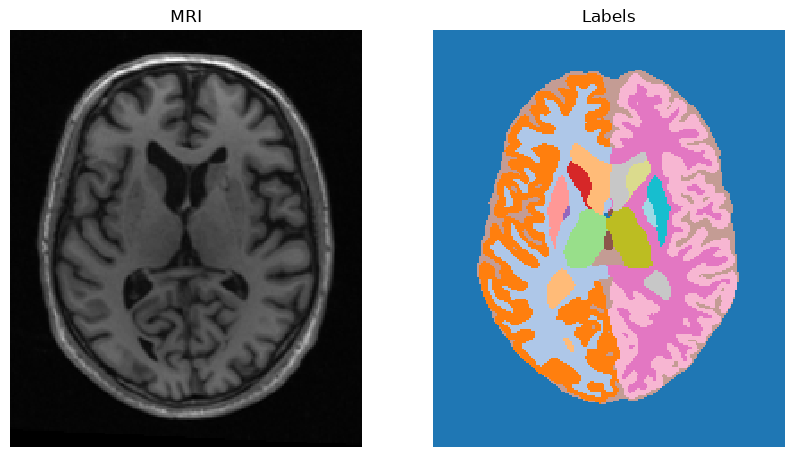

In [26]:
fname_img = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1w.nii.gz"
fname_seg = "data/inputs/sub-ADNI002S0295_ses-m000_space-MNI_T1wdseg_synthsr.nii.gz"
# npz = np.load(fname)
# dat = torch.as_tensor(npz['vol'][:, :, 112]).T[None]
# lab = torch.as_tensor(npz['seg'][:, :, 112]).T[None]

seg = nib.load(fname_seg).get_fdata()
img = nib.load(fname_img).get_fdata()

thal = np.argwhere(np.isin(seg, [10, 49]))
cx, cy, cz = thal.mean(0).astype(int) if len(thal) else np.array(seg.shape) // 2

seg = ufs.merge_seg96_to_seg36(seg) #map to 0,1,2,3
dat = torch.as_tensor(np.flipud(img[:, :, cz].T).copy())[None]
lab = torch.as_tensor(np.flipud(seg[:, :, cz].T).copy())[None]

lab = RelabelTransform()(lab) #map to 0,1,2,3,...,N
# convert to int
lab = lab.to(torch.int32)
print(f"dat shape: {dat.shape}, lab shape: {lab.shape}, unique labels: {torch.unique(lab)}")

show_image(dat, lab, title='MRI and Labels')

# plt.figure(figsize=(10, 10))
# plt.subplot(1, 2, 1)
# plt.imshow(dat.squeeze(), cmap='gray', interpolation='nearest')
# plt.axis('off')
# plt.title('MRI')
# plt.subplot(1, 2, 2)
# plt.imshow(lab.squeeze(), cmap='tab20', interpolation='nearest')
# plt.axis('off')
# plt.title('Labels')
# plt.show()

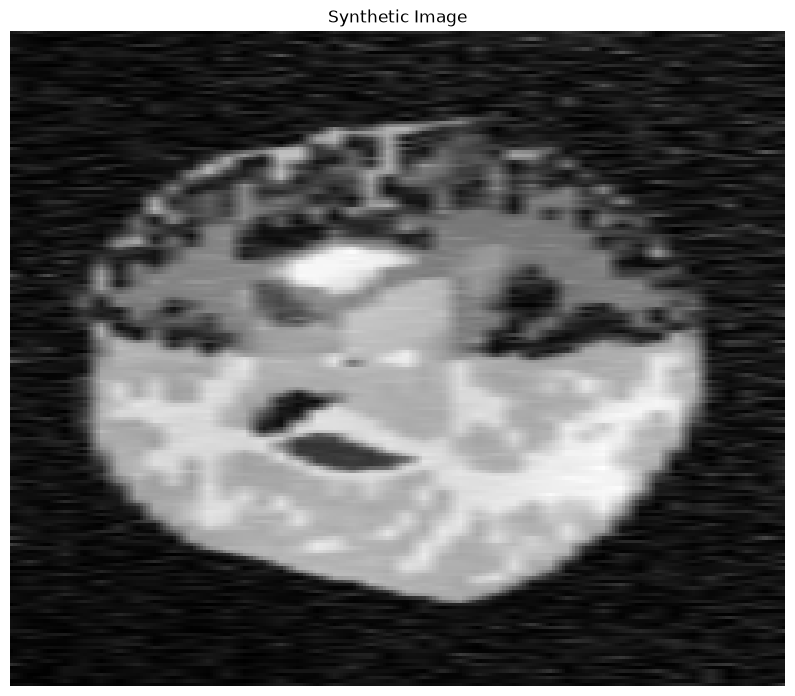

In [27]:
# Define a transform that applies, in sequence:
#   1) A Gaussian mixture, such that intensities are sampled with
#      different means and covariances in each label;
#   2) A series of common augmentations
#      (bias field, resampling, smoothing, ...).
trf = RandomGaussianMixtureTransform(background=0) + IntensityTransform()

# Apply the transformation to the label map
img = trf(lab)

# Display the resulting image
plt.figure(figsize=(10, 10))
plt.imshow(img.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Synthetic Image')
plt.show()

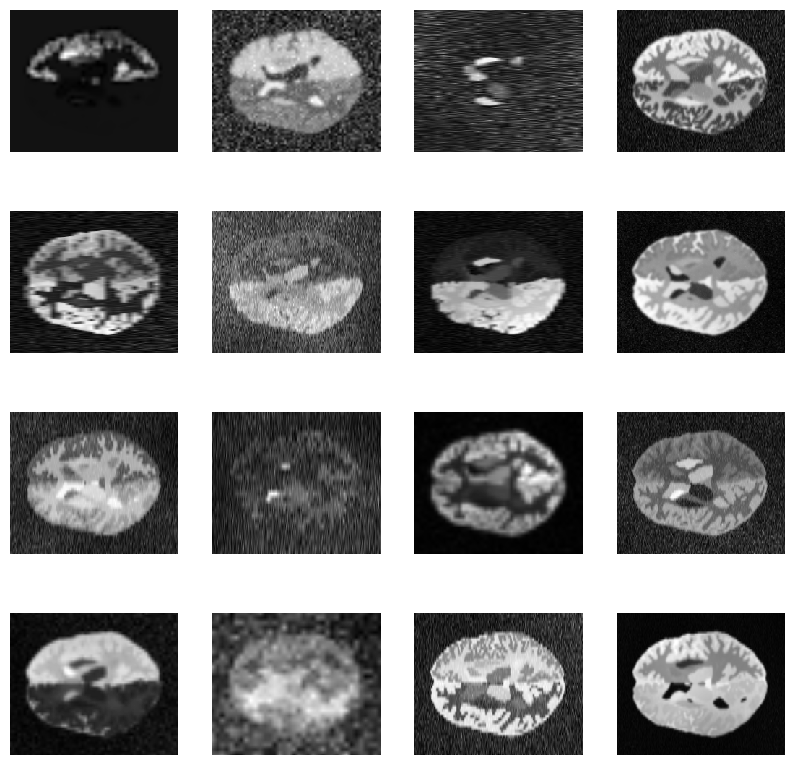

In [28]:
plotgrid = [4, 4]
plt.figure(figsize=(10, 10))

for i in range(plotgrid[0] * plotgrid[1]):

    # Sample an image
    img = trf(lab)

    # Display the image
    plt.subplot(*plotgrid, i+1)
    plt.imshow(img.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
    plt.axis('off')

plt.show()

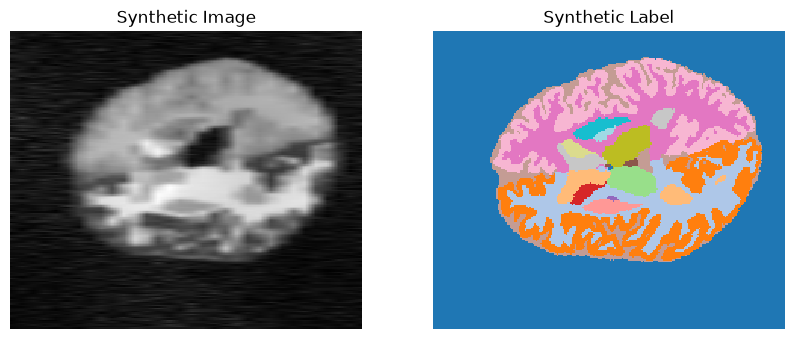

In [31]:
# Define a complete "label-to-image" transform
#   This is equivalent to the "GMM + intensity augmentation" sequence
#   used earlier, but also applies geometric transformations to the
#   label map, prior to the GMM.
trf = SynthFromLabelTransform()

# Apply the transform to generate a synthetic image and companion label map
img, newlab = trf(lab)

# Display the results
plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(img.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Synthetic Image')
plt.subplot(1, 2, 2)
plt.imshow(newlab.squeeze().T.flip(0), cmap='tab20', interpolation='nearest')
plt.axis('off')
plt.title('Synthetic Label')
plt.show()

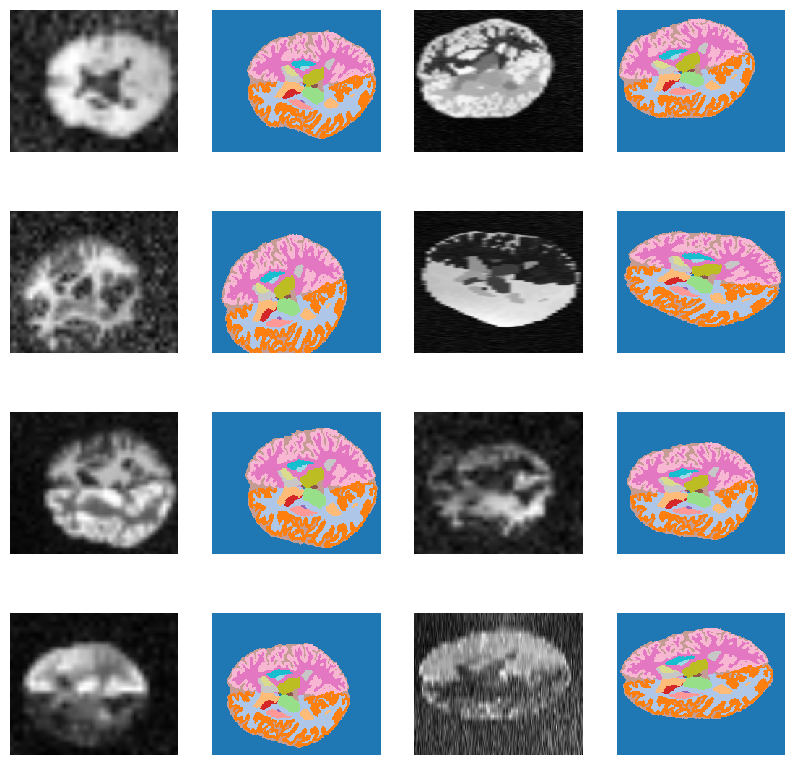

In [32]:
plotgrid = [4, 4]
plt.figure(figsize=(10, 10))

for i in range(plotgrid[0] * plotgrid[1]//2):

    # Generate an (image, label) pair
    img, newlab = trf(lab)

    # Display them
    plt.subplot(*plotgrid, 2*i+1)
    plt.imshow(img.squeeze().T.flip(0), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.subplot(*plotgrid, 2*i+2)
    plt.imshow(newlab.squeeze().T.flip(0), cmap='tab20', interpolation='nearest')
    plt.axis('off')

plt.show()